<a href="https://colab.research.google.com/github/HeiKol258/kobe-data-business-colab/blob/main/lecture02/lecture2_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/okumura-kobe/kobe-data-business/blob/main/lecture02/lecture2_notebook.ipynb)

# 後期大学院演習「データで動かす社会とビジネス」
## 第2回　演習 Notebook

**テーマ：意思決定から問いを立てる**

---

### この Notebook の使い方

- **STEP 1・2 はコードなし**：ワークシートに書いた問いと設計表を確認しながら進めてください
- **STEP 3 からコードを実行**：`____` を自分の設計表（ワークシートの②③④⑤）から埋めてください
- **STEP 4 はコードなし**：STEP 3 の結果を見て、問いを修正してください

---

| | |
|---|---|
| 学籍番号 | |
| 氏名 | |
| 実施日 | |

---
## Step 0　準備：ライブラリの読み込み

このセルは変更不要です。最初に実行してください。

In [1]:
# ライブラリの読み込み（変更不要）
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import urllib.request, zipfile, io, warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.3f}'.format)

matplotlib.rcParams['axes.spines.top']   = False
matplotlib.rcParams['axes.spines.right'] = False
matplotlib.rcParams['figure.figsize']    = (11, 4)

print('Ready')

Ready


---
## Step 1　データを読み込む

前回と同じデータを使います。GitHub から直接読み込みます。

In [2]:
# データの読み込み（変更不要）
url = "https://raw.githubusercontent.com/okumura-kobe/kobe-data-business/main/data/bike.csv"
df = pd.read_csv(url)

print(f'Rows: {df.shape[0]:,}  Cols: {df.shape[1]}')
print(f'Missing: {df.isnull().sum().sum()}')
df.head()

Rows: 17,379  Cols: 17
Missing: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.240,0.288,0.810,0.000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.220,0.273,0.800,0.000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.220,0.273,0.800,0.000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.240,0.288,0.750,0.000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.240,0.288,0.750,0.000,0,1,1


---
## STEP 1　最初の問いを記録する

**ここはコードを書かずに、ワークシートの内容を転記してください。**

In [ ]:
# ワークシート STEP 1 で書いた『最初の問い』を転記する
#
# 【最初の問い】
#
# 平日と休日で時間帯別の利用件数はどのように異なり、再配置を重点化すべき時間帯はいつか。
#

---
## STEP 2　分析設計表の確認

**ここもコードは不要です。ワークシートの設計表を確認してください。**

今から実行するコードに、以下を当てはめます：

| 項目 | ワークシートに書いた内容 |
|---|---|
| ③ 目的変数 | cnt |
| ④ 比較・説明変数 | workingday, hr, weathersit |
| ⑤ 必要なデータ | hr, workingday, weathersit, cnt, registered, casual|
| ⑦ 判断基準 | 各区別の平均cntの上位3時間帯を重点配置とする |

In [ ]:
# 設計表の内容をコメントとして記録する（変数名で書く）
#
# ③ 目的変数（例: 'cnt', 'registered', 'casual'）：
#
# ④ 比較変数（例: 'workingday', 'weathersit', 'hr'）：
#
# ⑦ 判断基準（どんな結果が出れば、どう判断するか）：
#

---
## STEP 3　データで確認する（25〜40分）

### 3-1　設計表で選んだ変数を確認する

ワークシートの⑤で特定した変数を確認します。
`____` に自分が選んだ変数名を入れてください。

In [3]:
# 3-1　必要な変数の基本統計を確認する
# ⑤で選んだ変数を確認する
df[['hr', 'workingday', 'weathersit', 'cnt', 'registered', 'casual']].describe()

,hr,workingday,weathersit,cnt,registered,casual
count,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000
mean,11.547,0.683,1.425,189.463,153.787,35.676
std,6.914,0.465,0.639,181.388,151.357,49.305
min,0.000,0.000,1.000,1.000,0.000,0.000
25%,6.000,0.000,1.000,40.000,34.000,4.000
50%,12.000,1.000,1.000,142.000,115.000,17.000
75%,18.000,1.000,2.000,281.000,220.000,48.000
max,23.000,1.000,4.000,977.000,886.000,367.000


### 3-2　目的変数を比較変数で集計する

③目的変数を④比較変数で分けて平均を見ます。

In [4]:
# 3-2　目的変数を比較変数で集計する
# 平日・休日と時間帯別に平均利用件数を確認する
result = df.groupby(['workingday', 'hr'])['cnt'].mean()
print(result.round(1))

workingday  hr
0           0     90.800
            1     69.500
            2     53.200
            3     25.800
            4      8.300
            5      8.700
            6     18.700
            7     43.400
            8    105.700
            9    171.600
            10   255.900
            11   315.300
            12   366.300
            13   372.700
            14   364.600
            15   358.800
            16   352.700
            17   323.500
            18   281.100
            19   231.700
            20   174.700
            21   142.100
            22   116.100
            23    85.900
1           0     36.800
            1     16.600
            2      8.700
            3      4.900
            4      5.400
            5     24.900
            6    102.500
            7    290.600
            8    477.000
            9    241.500
            10   135.400
            11   158.200
            12   200.800
            13   198.400
            14   183.600
          

### 3-3【発展】可視化する

時間に余裕があれば、自分の問いに合ったグラフを作成してください。

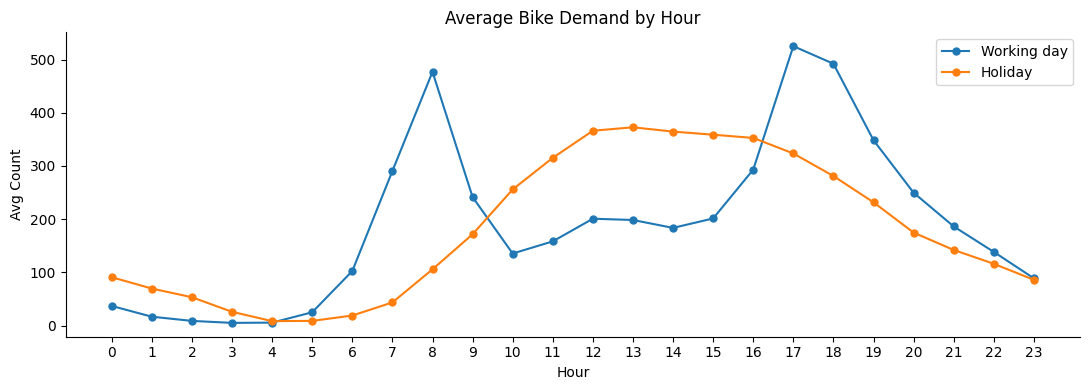

In [8]:
# 3-3　平日・休日別の時間帯パターンを可視化する
plot_data = df.groupby(['hr', 'workingday'])['cnt'].mean().unstack()

fig, ax = plt.subplots()
ax.plot(plot_data.index, plot_data[1], marker='o', markersize=5, label='Working day')
ax.plot(plot_data.index, plot_data[0], marker='o', markersize=5, label='Holiday')
ax.set_title('Average Bike Demand by Hour')
ax.set_xlabel('Hour')
ax.set_ylabel('Avg Count')
ax.set_xticks(range(0, 24, 1))
ax.legend()
plt.tight_layout()
plt.show()

---
## STEP 4　問いを修正する（40〜50分）

**データを見た後で、最初の問いを見直してください。**
コードは不要です。ワークシートの STEP 4 に記入してください。

In [ ]:
# STEP 4：問いの修正をここに記録する
#
# 【修正後の問い】
#
# 平日・休日別に、時間帯別の平均 cnt と登録・カジュアル利用者の内訳はどう異なり、重点配置すべき上位3時間帯はいつか。
#
# 【なぜ修正したか / しなかったか】
#
# データにステーション変数がないため『どこ』を外した。また、利用者区分と上位3時間帯という比較軸・判断基準を加え、実際に検証できる問いにした。
#

---
## ディスカッション準備

授業のディスカッション（10分）に向けて、以下を考えてください。

In [ ]:
# ディスカッション：問いの変化を記録する
#
# ① 自分の問いはどう変わったか？（一言で）
#
#    → 広い問いから、データで答えられる時間帯別・利用者区分別の比較に変えた。
#
# ② 問いが変わった（変わらなかった）理由は？
#
#    → 駅情報がないため『どこ』を外し、実際に確認できる変数に絞った。
#
# ③ 設計表の⑦判断基準を振り返って、もっと具体的にできるか？
#
#    → 平日・休日ごとに平均 cnt が上位3時間帯に入れば重点配置する、と具体化した。
#

---
## まとめ

### 今日学んだこと

| STEP | 内容 |
|---|---|
| STEP 1 | 意思決定課題から問いを自由に書いた |
| STEP 2 | 8項目の分析設計表を埋めた |
| STEP 3 | データで設計の実行可能性を確認した |
| STEP 4 | 問いを修正した（または確信を深めた） |

### 今日の核心

> **問いが変われば、分析が変わる。分析が変われば、判断が変わる。**
> データを見た後に問いを直せる人が、データを使いこなせる人だ。

---

### 次回（第3回）：データを読み、比較する

**事前課題**
- BEEF+ の第3回配布資料を読む
- 今日の設計表の⑦判断基準をさらに具体化しておく